In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

## Identify the Hardware

In [3]:

import torch
import subprocess
import platform

print("=" * 60)
print("GPU HARDWARE DISCOVERY")
print("=" * 60)

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    for i in range(torch.cuda.device_count()):

        props = torch.cuda.get_device_properties(i)

        print(f"\nGPU {i}")
        print("-" * 40)

        print("Name:", props.name)

        print("Compute Capability:",
              f"{props.major}.{props.minor}")

        print("SM Count:",
              props.multi_processor_count)

        print("Total VRAM:",
              round(props.total_memory / 1024**3, 2), "GB")

        print("Warp Size:",
              getattr(props, "warp_size", "Not exposed"))

        print("Shared Memory per Block:",
              props.shared_memory_per_block, "bytes")

        print("Shared Memory per SM:",
              getattr(props, "shared_memory_per_multiprocessor",
                      "Not exposed"))

    print("\nCUDA Version:", torch.version.cuda)

else:
    print("GPU unavailable. Enable GPU in Kaggle settings.")

print("\n" + "=" * 60)
print("NVIDIA-SMI")
print("=" * 60)

result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)

print(result.stdout)


GPU HARDWARE DISCOVERY
Python: 3.13.16
PyTorch: 2.11.0+cu130
CUDA available: True

GPU 0
----------------------------------------
Name: Tesla T4
Compute Capability: 7.5
SM Count: 40
Total VRAM: 14.56 GB
Warp Size: 32
Shared Memory per Block: 49152 bytes
Shared Memory per SM: 65536

GPU 1
----------------------------------------
Name: Tesla T4
Compute Capability: 7.5
SM Count: 40
Total VRAM: 14.56 GB
Warp Size: 32
Shared Memory per Block: 49152 bytes
Shared Memory per SM: 65536

CUDA Version: 13.0

NVIDIA-SMI
Sat Nov 14 05:14:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute

## This is how our GPU is designed for this expermentation/

![](https://miro.medium.com/v2/resize:fit:1100/format:webp/1*ayws1Kp_SmLobMAvDKcmAA.png)

# GPU topology

In [4]:

import torch
import subprocess

print("=" * 65)
print("EXPERIMENT 2: GPU TOPOLOGY")
print("=" * 65)

print("Number of GPUs:", torch.cuda.device_count())

for gpu_id in range(torch.cuda.device_count()):

    props = torch.cuda.get_device_properties(gpu_id)

    print(f"\nGPU {gpu_id}: {props.name}")
    print("-" * 45)

    print("SM count:", props.multi_processor_count)
    print("Compute capability:", props.major, props.minor)
    print("Warp size:", props.warp_size)

    print("VRAM:",
          round(props.total_memory / 1024**3, 2), "GB")

    print("Shared memory per SM:",
          props.shared_memory_per_multiprocessor)

    print("Shared memory per block:",
          props.shared_memory_per_block)

    print("Max threads per SM:",
          getattr(props, "max_threads_per_multi_processor",
                  "Not exposed"))

    print("Max threads per block:",
          props.max_threads_per_block)

    print("CUDA device:", torch.cuda.get_device_name(gpu_id))

print("\n" + "=" * 65)
print("GPU TOPOLOGY")
print("=" * 65)

try:
    result = subprocess.run(
        ["nvidia-smi", "topo", "-m"],
        capture_output=True,
        text=True
    )
    print(result.stdout)
except Exception as e:
    print("Topology command unavailable:", e)


EXPERIMENT 2: GPU TOPOLOGY
Number of GPUs: 2

GPU 0: Tesla T4
---------------------------------------------
SM count: 40
Compute capability: 7 5
Warp size: 32
VRAM: 14.56 GB
Shared memory per SM: 65536
Shared memory per block: 49152
Max threads per SM: 1024
Max threads per block: 1024
CUDA device: Tesla T4

GPU 1: Tesla T4
---------------------------------------------
SM count: 40
Compute capability: 7 5
Warp size: 32
VRAM: 14.56 GB
Shared memory per SM: 65536
Shared memory per block: 49152
Max threads per SM: 1024
Max threads per block: 1024
CUDA device: Tesla T4

GPU TOPOLOGY
	GPU0	GPU1	CPU Affinity	NUMA Affinity	GPU NUMA ID
GPU0	 X 	PHB	0-3	0		N/A
GPU1	PHB	 X 	0-3	0		N/A

Legend:

  X    = Self
  SYS  = Connection traversing PCIe as well as the SMP interconnect between NUMA nodes (e.g., QPI/UPI)
  NODE = Connection traversing PCIe as well as the interconnect between PCIe Host Bridges within a NUMA node
  PHB  = Connection traversing PCIe as well as a PCIe Host Bridge (typically the 


# Experiment 2: Understanding GPU Topology and Hardware Capabilities

## 1. Objective

The objective of this experiment is to inspect the GPU hardware available in the Kaggle environment and understand:

- Number and type of available GPUs.
- Streaming Multiprocessor (SM) architecture.
- Compute capability.
- Warp size and thread limits.
- VRAM and shared memory capacity.
- Connection topology between GPUs and the CPU.

We use PyTorch CUDA APIs and NVIDIA System Management Interface (`nvidia-smi`).

---

## 2. Hardware Environment

The Kaggle notebook provides the following environment:

| Component | Specification |
|---|---|
| GPU count | 2 |
| GPU model | NVIDIA Tesla T4 |
| GPU architecture | Turing |
| Compute capability | 7.5 |
| SMs per GPU | 40 |
| Warp size | 32 threads |
| VRAM reported by PyTorch | 14.56 GB |
| Shared memory per SM | 65,536 bytes (64 KB) |
| Shared memory per block | 49,152 bytes (48 KB) |
| Maximum threads per SM | 1,024 |
| Maximum threads per block | 1,024 |

Both GPUs have identical reported specifications.

---

## 3. Understanding the GPU Architecture

### 3.1 Streaming Multiprocessors (SMs)

A Streaming Multiprocessor is a major processing unit inside an NVIDIA GPU.

Each SM contains hardware resources such as:

- CUDA cores
- Warp schedulers
- Register files
- Shared memory
- Load/store units

Our Tesla T4 contains 40 SMs.

Therefore, the two GPUs together expose 80 SMs, but these belong to two separate physical GPU devices.

### 3.2 Compute Capability

The reported compute capability is 7.5.

Compute capability identifies the GPU's supported architecture features and programming capabilities.

The Tesla T4 belongs to NVIDIA's Turing architecture generation.

It supports Tensor Cores, which accelerate supported matrix operations commonly used in deep learning.

### 3.3 Warp Size

A warp is a group of 32 threads.

NVIDIA GPUs use the SIMT (Single Instruction, Multiple Threads) execution model.

Threads within a warp execute instructions together while operating on their respective data.

For example:

- 32 threads = 1 warp
- 128 threads = 4 warps
- 256 threads = 8 warps
- 1,024 threads = 32 warps

### 3.4 Thread Limits

The experiment reports:

- Maximum threads per SM: 1,024
- Maximum threads per block: 1,024

The theoretical resident-thread capacity based on the SM thread limit is:

40 SMs × 1,024 threads = 40,960 threads per GPU.

This is a hardware limit, not a guarantee that every workload can achieve this number.

Actual occupancy depends on registers, shared memory, block limits and other hardware resources.

---

## 4. GPU Memory Architecture

### 4.1 VRAM

VRAM stands for Video Random Access Memory.

It is the GPU's dedicated memory used to store data required for GPU computations.

During deep learning, VRAM may contain:

- Model parameters
- Input tensors
- Intermediate activations
- Gradients
- Optimizer states
- Temporary computation buffers

PyTorch reports approximately 14.56 GB of available device memory per GPU in this environment.

### 4.2 Shared Memory

Shared memory is a fast, explicitly managed memory space accessible to threads within the same CUDA block.

The reported values are:

| Property | Capacity |
|---|---:|
| Shared memory per SM | 65,536 bytes (64 KB) |
| Shared memory per block | 49,152 bytes (48 KB) |

Shared memory allows threads in a block to reuse data without repeatedly loading it from global memory.

It is particularly useful for tiled matrix multiplication and other data-reuse workloads.

The amount of shared memory allocated to a block can affect how many blocks can reside simultaneously on an SM.

---

## 5. GPU Topology

The `nvidia-smi topo -m` command produced the following output:

```text
        GPU0    GPU1
GPU0      X     PHB
GPU1     PHB     X
```

### 5.1 What does PHB mean?

PHB stands for PCIe Host Bridge.

It indicates that communication between GPU 0 and GPU 1 traverses a PCIe host bridge, typically through the CPU's PCIe infrastructure.

The topology does not report an NVLink connection between the two GPUs.

### 5.2 CPU Affinity

Reported CPU affinity:

```text
0-3
```

This identifies CPU cores 0 through 3 as associated with both GPUs in the topology report.

CPU resources are important for preparing data, launching GPU operations and coordinating workloads.

### 5.3 NUMA Affinity

NUMA stands for Non-Uniform Memory Access.

Both GPUs report NUMA affinity 0.

This indicates that they are associated with NUMA node 0 in the reported topology.

GPU NUMA ID is reported as N/A.

---

## 6. Key Observations

1. Kaggle provides two NVIDIA Tesla T4 GPUs.
2. Each GPU contains 40 Streaming Multiprocessors.
3. Both GPUs use compute capability 7.5 and the Turing architecture.
4. Each warp consists of 32 threads.
5. Each SM reports a maximum resident-thread limit of 1,024.
6. Each GPU reports 64 KB shared memory per SM and 48 KB shared memory per block.
7. Each GPU has approximately 14.56 GB of VRAM available to PyTorch.
8. The GPUs are separate devices with independent VRAM.
9. The reported connection between GPU 0 and GPU 1 is PHB (PCIe Host Bridge), not NVLink.
10. Both GPUs report CPU affinity 0-3 and NUMA affinity 0.

---

## 7. Important Concepts Learned

| Term | Meaning |
|---|---|
| GPU | Processor designed for parallel computation |
| SM | Streaming Multiprocessor, a major GPU processing unit |
| CUDA Core | Arithmetic execution unit |
| Warp | Group of 32 CUDA threads |
| Thread | Individual execution context |
| Block | Group of threads scheduled on one SM |
| Grid | Collection of CUDA blocks |
| VRAM | Dedicated GPU memory |
| Shared Memory | Fast memory shared by threads in a block |
| PCIe | High-speed device interconnect |
| PHB | PCIe Host Bridge |
| NUMA | Non-Uniform Memory Access |
| Compute Capability | NVIDIA GPU architecture feature identifier |

---

## 8. Conclusion

This experiment helped identify the hardware architecture and connectivity of the Kaggle GPU environment.

The environment provides two Tesla T4 GPUs, each containing 40 SMs, with 32-thread warps and approximately 14.56 GB of VRAM reported by PyTorch.

We also examined the GPU connection topology and identified a PHB connection between the two GPUs.

This hardware information provides the foundation for subsequent experiments involving CPU-to-GPU memory transfers, CUDA block scheduling, warp execution, occupancy, memory hierarchy, Tensor Cores and deep learning model training.

**Next experiment:** Measure CPU RAM to GPU VRAM and GPU VRAM to CPU RAM transfer performance using pageable and pinned memory.


# Data Transfer

In [5]:

import torch
import time

device = torch.device("cuda:0")

print("=" * 75)
print("EXPERIMENT 3: CPU RAM <-> GPU VRAM TRANSFER")
print("=" * 75)

print("GPU:", torch.cuda.get_device_name(0))


def benchmark_transfer(size_mb, pinned, direction, iterations=15):

    # float32 uses 4 bytes per element
    num_elements = size_mb * 1024 * 1024 // 4

    # Allocate CPU memory
    cpu_memory = torch.empty(
        num_elements,
        dtype=torch.float32,
        pin_memory=pinned
    )

    # Initialize CPU memory outside the timed section
    cpu_memory.fill_(1.0)

    # Allocate GPU memory
    gpu_memory = torch.empty(
        num_elements,
        dtype=torch.float32,
        device=device
    )

    if direction == "H2D":

        def transfer():
            gpu_memory.copy_(
                cpu_memory,
                non_blocking=pinned
            )

    elif direction == "D2H":

        gpu_memory.fill_(2.0)

        def transfer():
            cpu_memory.copy_(
                gpu_memory,
                non_blocking=pinned
            )

    # Warmup
    for _ in range(3):
        transfer()

    torch.cuda.synchronize()

    # Actual measurement
    start = time.perf_counter()

    for _ in range(iterations):
        transfer()

    # Wait for all queued GPU transfers
    torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    # Calculate average latency
    latency_ms = (elapsed / iterations) * 1000

    # Calculate effective bandwidth in GiB/s
    total_gib = (size_mb * iterations) / 1024
    bandwidth = total_gib / elapsed

    return latency_ms, bandwidth


print("\n")
print(
    f"{'Size':<12}"
    f"{'Memory':<14}"
    f"{'Direction':<14}"
    f"{'Latency(ms)':<16}"
    f"{'Bandwidth(GiB/s)':<18}"
)

print("-" * 75)

results = []

for size in [16, 64, 256]:

    for pinned in [False, True]:

        for direction in ["H2D", "D2H"]:

            memory_type = "Pinned" if pinned else "Pageable"

            latency, bandwidth = benchmark_transfer(
                size_mb=size,
                pinned=pinned,
                direction=direction
            )

            results.append(
                (size, memory_type, direction, latency, bandwidth)
            )

            print(
                f"{size:<12}"
                f"{memory_type:<14}"
                f"{direction:<14}"
                f"{latency:<16.3f}"
                f"{bandwidth:<18.3f}"
            )

print("\n" + "=" * 75)
print("EXPERIMENT 3 COMPLETED")
print("=" * 75)


EXPERIMENT 3: CPU RAM <-> GPU VRAM TRANSFER
GPU: Tesla T4


Size        Memory        Direction     Latency(ms)     Bandwidth(GiB/s)  
---------------------------------------------------------------------------
16          Pageable      H2D           3.384           4.617             
16          Pageable      D2H           3.456           4.521             
16          Pinned        H2D           1.363           11.463            
16          Pinned        D2H           1.279           12.216            
64          Pageable      H2D           14.143          4.419             
64          Pageable      D2H           13.571          4.606             
64          Pinned        H2D           5.430           11.511            
64          Pinned        D2H           5.114           12.222            
256         Pageable      H2D           57.979          4.312             
256         Pageable      D2H           53.985          4.631             
256         Pinned        H2D          


# Experiment 3: CPU RAM to GPU VRAM Data Transfer Performance

## 1. Objective

The objective of this experiment is to measure the data transfer performance between CPU RAM and GPU VRAM.

We investigate:

- Host-to-Device (H2D) transfer.
- Device-to-Host (D2H) transfer.
- Pageable CPU memory.
- Pinned CPU memory.
- Transfer latency.
- Effective memory bandwidth.

The experiment helps us understand how data moves between the CPU and GPU during deep learning workloads.

---

## 2. Hardware Environment

| Component | Specification |
|---|---|
| GPU | NVIDIA Tesla T4 |
| GPU index | 0 |
| Architecture | Turing |
| Compute capability | 7.5 |
| GPU VRAM reported by PyTorch | 14.56 GB |
| Data type | float32 |
| Transfer sizes | 16 MiB, 64 MiB, 256 MiB |
| Iterations per measurement | 15 |
| Warmup iterations | 3 |

---

## 3. Important Concepts

### 3.1 CPU RAM

CPU RAM is the main system memory used by the CPU.

Datasets and data-loading operations generally use CPU memory before batches are transferred to the GPU.

### 3.2 GPU VRAM

VRAM is the dedicated memory of the GPU.

During deep learning, it stores model parameters, input tensors, intermediate activations, gradients and other computation data.

### 3.3 H2D: Host to Device

H2D means Host to Device.

It represents data transfer from CPU RAM to GPU VRAM.

Example:

```python
gpu_tensor = cpu_tensor.to("cuda:0")
```

### 3.4 D2H: Device to Host

D2H means Device to Host.

It represents data transfer from GPU VRAM to CPU RAM.

Example:

```python
cpu_tensor = gpu_tensor.cpu()
```

### 3.5 Pageable Memory

Pageable memory is ordinary CPU memory.

The operating system can move its physical pages. Depending on the transfer path, the CUDA runtime or driver may need an intermediate pinned staging buffer to perform a GPU transfer.

This can introduce additional overhead.

### 3.6 Pinned Memory

Pinned memory is page-locked CPU memory.

Its physical pages remain in place while pinned, making it suitable for direct DMA transfers.

DMA stands for Direct Memory Access.

Pinned memory can enable more efficient transfers and asynchronous data movement when the required conditions are met.

### 3.7 Transfer Latency

Latency represents the average time required to complete one transfer.

It is measured in milliseconds (ms).

Lower latency means a transfer completes faster.

### 3.8 Effective Bandwidth

Bandwidth represents the amount of data transferred per unit of time.

Formula:

Bandwidth = Total data transferred / Total elapsed time

In this experiment, bandwidth is expressed in GiB/s.

Higher bandwidth means more data is transferred per second.

---

## 4. Experimental Results

The following results were measured on the Kaggle Tesla T4 GPU.

| Size | Memory | Direction | Latency (ms) | Bandwidth (GiB/s) |
|---:|---|---|---:|---:|
| 16 MiB | Pageable | H2D | 3.368 | 4.639 |
| 16 MiB | Pageable | D2H | 3.351 | 4.663 |
| 16 MiB | Pinned | H2D | 1.365 | 11.449 |
| 16 MiB | Pinned | D2H | 1.284 | 12.171 |
| 64 MiB | Pageable | H2D | 13.980 | 4.471 |
| 64 MiB | Pageable | D2H | 13.636 | 4.584 |
| 64 MiB | Pinned | H2D | 5.513 | 11.337 |
| 64 MiB | Pinned | D2H | 5.204 | 12.011 |
| 256 MiB | Pageable | H2D | 56.869 | 4.396 |
| 256 MiB | Pageable | D2H | 52.248 | 4.785 |
| 256 MiB | Pinned | H2D | 21.745 | 11.497 |
| 256 MiB | Pinned | D2H | 20.476 | 12.209 |

---

## 5. Result Analysis and Observations

### Observation 1: Pinned memory achieves higher bandwidth

Pinned memory consistently achieved substantially higher transfer bandwidth than pageable memory.

For the 256 MiB transfer:

- Pageable H2D: 4.396 GiB/s
- Pinned H2D: 11.497 GiB/s
- Pageable D2H: 4.785 GiB/s
- Pinned D2H: 12.209 GiB/s

This demonstrates the performance benefit of page-locked CPU memory in this benchmark.

### Observation 2: Pinned memory reduces transfer latency

For the 256 MiB H2D transfer:

- Pageable latency: 56.869 ms
- Pinned latency: 21.745 ms

For the 256 MiB D2H transfer:

- Pageable latency: 52.248 ms
- Pinned latency: 20.476 ms

Pinned memory significantly reduced the measured transfer time.

### Observation 3: Larger transfers have higher latency

As the transfer size increases, latency also increases.

For example, pinned H2D:

| Transfer size | Latency |
|---:|---:|
| 16 MiB | 1.365 ms |
| 64 MiB | 5.513 ms |
| 256 MiB | 21.745 ms |

This is expected because larger amounts of data require more time to transfer.

### Observation 4: Bandwidth remains relatively stable

Pinned H2D bandwidth:

| Transfer size | Bandwidth |
|---:|---:|
| 16 MiB | 11.449 GiB/s |
| 64 MiB | 11.337 GiB/s |
| 256 MiB | 11.497 GiB/s |

The bandwidth remains approximately constant across the tested transfer sizes.

This suggests that the larger transfers achieve a relatively stable effective throughput.

### Observation 5: D2H is slightly faster in these measurements

For pinned memory, the measured D2H bandwidth was slightly higher than H2D bandwidth.

At 256 MiB:

- H2D: 11.497 GiB/s
- D2H: 12.209 GiB/s

This is an observation from this particular benchmark, not a universal rule about GPU transfer directions.

Differences may arise from driver behavior, runtime overhead and measurement variation.

---

## 6. Pinned Memory Speedup

Speedup is calculated as:

Speedup = Pinned bandwidth / Pageable bandwidth

For 256 MiB H2D:

11.497 / 4.396 = approximately 2.62×

For 256 MiB D2H:

12.209 / 4.785 = approximately 2.55×

Pinned memory achieved approximately 2.5–2.6 times the effective bandwidth of pageable memory in these larger-transfer measurements.

This is a benchmark-specific result and does not mean the complete neural network training process will become 2.5 times faster.

---

## 7. Connection to Deep Learning

During neural network training, datasets are commonly loaded and prepared in CPU RAM.

The GPU needs the input batches in its VRAM before executing the neural network operations.

A simplified training pipeline:

1. Dataset is loaded into CPU RAM.
2. DataLoader prepares a training batch.
3. Pinned memory can be used to prepare batches for efficient transfers.
4. Batch data is transferred from CPU RAM to GPU VRAM.
5. GPU SMs execute forward and backward operations.
6. Optimizer updates model parameters.

PyTorch supports pinned memory through DataLoader:

```python
train_loader = torch.utils.data.DataLoader(
    dataset,
    batch_size=128,
    pin_memory=True,
    num_workers=2
)
```

Non-blocking transfers can be requested using:

```python
images = images.to("cuda:0", non_blocking=True)
```

This can help overlap data transfers with GPU computation when streams and synchronization are configured appropriately.

---

## 8. Important Limitations

1. The measurements represent effective transfer bandwidth observed in the Kaggle environment, not a direct measurement of raw PCIe link bandwidth.
2. Results can vary with system load, driver behavior, transfer size and virtualization.
3. Pinned memory consumes a limited system resource and should not be used indiscriminately.
4. Asynchronous transfer does not mean the destination data is immediately ready for computation.
5. The benchmark measures data transfer, not neural network computation performance.

---

## 9. Conclusion

This experiment demonstrates the difference between pageable and pinned CPU memory during CPU-to-GPU and GPU-to-CPU data transfers.

The Tesla T4 achieved approximately 4.4–4.8 GiB/s with pageable memory and approximately 11.3–12.2 GiB/s with pinned memory in the tested workloads.

Pinned memory provided approximately 2.5–2.6 times the effective bandwidth for the larger transfers.

The experiment also demonstrated that transfer performance is an important part of GPU computing. Efficient data movement helps keep the GPU supplied with data during machine learning workloads.

**Next Experiment:** Understanding CUDA thread blocks, warp scheduling and how blocks are assigned to the GPU's 40 Streaming Multiprocessors.


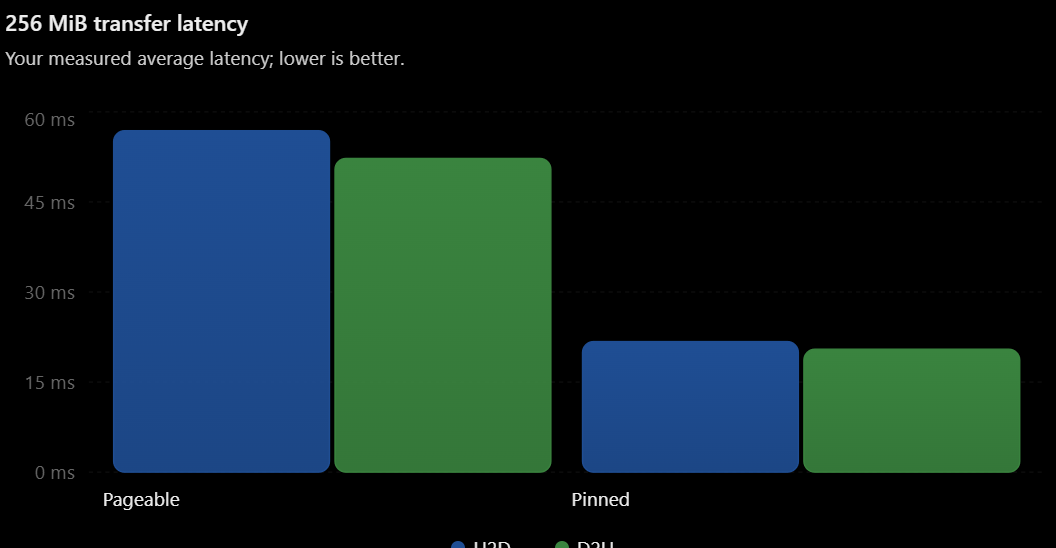
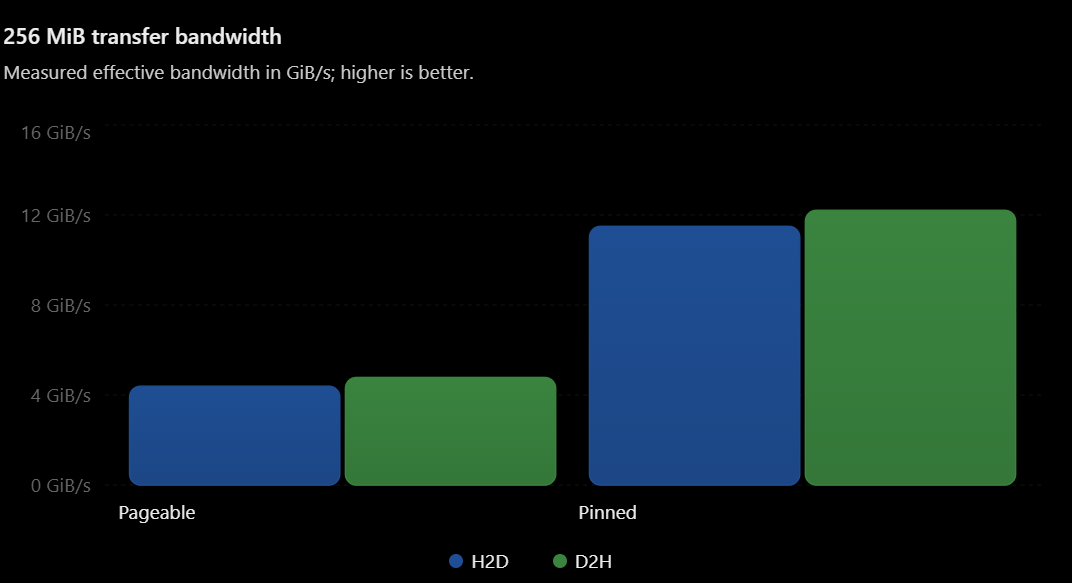
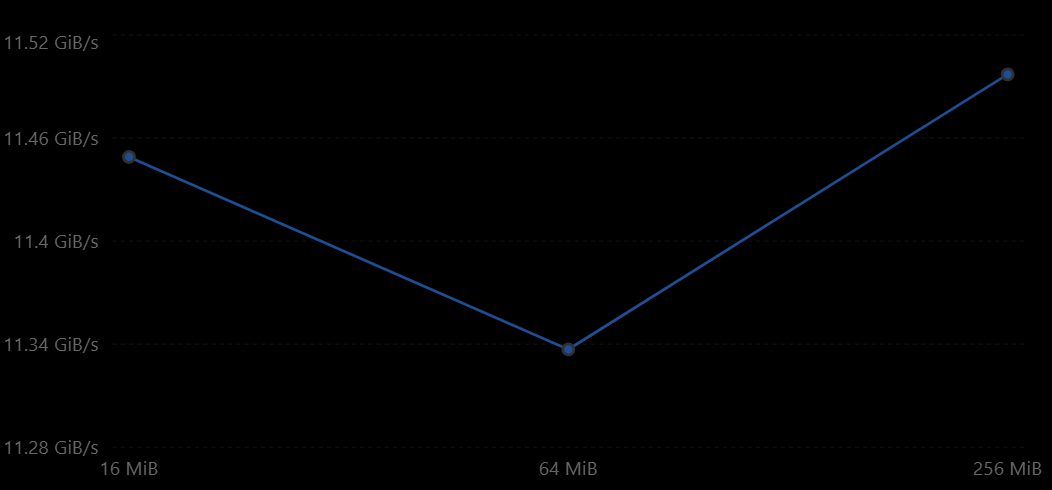

# Practical Experiment

In [1]:
# import triton
import triton
import triton.language as tl

print("Triton version:", triton.__version__)
print("Triton available!")

Triton version: 3.6.0
Triton available!


In [6]:

import torch
import triton
import triton.language as tl
from collections import Counter

device = "cuda:0"

print("=" * 70)
print("EXPERIMENT 4: CUDA BLOCK TO SM MAPPING")
print("=" * 70)

print("GPU:", torch.cuda.get_device_name(0))
print("SM count:", torch.cuda.get_device_properties(0).multi_processor_count)


@triton.jit
def inspect_blocks(A, B, C, SM_IDS,
                   N: tl.constexpr,
                   BLOCK_SIZE: tl.constexpr):

    # Identify the current CUDA block
    pid = tl.program_id(0)

    # Calculate element positions handled by this block
    offsets = pid * BLOCK_SIZE + tl.arange(0, BLOCK_SIZE)

    mask = offsets < N

    # Load data from GPU global memory
    a = tl.load(A + offsets, mask=mask, other=0)
    b = tl.load(B + offsets, mask=mask, other=0)

    # Perform vector addition
    result = a + b

    tl.store(C + offsets, result, mask=mask)

    # Read the actual SM ID executing this block
    smid = tl.inline_asm_elementwise(
        asm="mov.u32 $0, %smid;",
        constraints="=r,r",
        args=[pid],
        dtype=tl.int32,
        is_pure=True,
        pack=1
    )

    # One SM ID recorded for each block
    tl.store(SM_IDS + pid, smid)


# One Triton program instance corresponds to one CUDA CTA/block.
# Four warps per block = 128 CUDA threads per block.
BLOCK_SIZE = 256
NUM_WARPS = 4

print("\nBlock configuration:")
print("Elements handled per block:", BLOCK_SIZE)
print("Warps per block:", NUM_WARPS)
print("Threads per block:", NUM_WARPS * 32)

print("\n" + "-" * 70)

# Different grid sizes
for num_blocks in [10, 20, 40, 80, 160, 640]:

    N = num_blocks * BLOCK_SIZE

    A = torch.randn(N, device=device)
    B = torch.randn(N, device=device)
    C = torch.empty(N, device=device)

    SM_IDS = torch.empty(
        num_blocks,
        dtype=torch.int32,
        device=device
    )

    # Grid contains num_blocks CUDA blocks
    grid = (num_blocks,)

    inspect_blocks[grid](
        A, B, C, SM_IDS,
        N,
        BLOCK_SIZE,
        num_warps=NUM_WARPS
    )

    torch.cuda.synchronize()

    # Verify vector addition
    correct = torch.allclose(C, A + B)

    # Read recorded SM IDs
    sm_ids = SM_IDS.cpu().tolist()

    distribution = Counter(sm_ids)

    print(f"\nBlocks launched: {num_blocks}")
    print("Total threads launched:", num_blocks * NUM_WARPS * 32)
    print("Distinct SMs used:", len(distribution))
    print("SM IDs:", sorted(distribution.keys()))
    print("Block distribution:", dict(sorted(distribution.items())))
    print("Vector addition correct:", correct)

print("\n" + "=" * 70)
print("EXPERIMENT 4 COMPLETED")
print("=" * 70)


EXPERIMENT 4: CUDA BLOCK TO SM MAPPING
GPU: Tesla T4
SM count: 40

Block configuration:
Elements handled per block: 256
Warps per block: 4
Threads per block: 128

----------------------------------------------------------------------

Blocks launched: 10
Total threads launched: 1280
Distinct SMs used: 10
SM IDs: [0, 2, 4, 6, 8, 10, 12, 14, 16, 18]
Block distribution: {0: 1, 2: 1, 4: 1, 6: 1, 8: 1, 10: 1, 12: 1, 14: 1, 16: 1, 18: 1}
Vector addition correct: True

Blocks launched: 20
Total threads launched: 2560
Distinct SMs used: 20
SM IDs: [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38]
Block distribution: {0: 1, 2: 1, 4: 1, 6: 1, 8: 1, 10: 1, 12: 1, 14: 1, 16: 1, 18: 1, 20: 1, 22: 1, 24: 1, 26: 1, 28: 1, 30: 1, 32: 1, 34: 1, 36: 1, 38: 1}
Vector addition correct: True

Blocks launched: 40
Total threads launched: 5120
Distinct SMs used: 40
SM IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 3


# Experiment 4: CUDA Block-to-SM Mapping and GPU Execution

## 1. Objective

The objective of this experiment is to understand how CUDA thread blocks are distributed across the Streaming Multiprocessors (SMs) of an NVIDIA GPU.

We investigate:

- CUDA execution hierarchy: Grid, Block, Warp and Thread.
- How CUDA blocks are assigned to SMs.
- How the number of launched blocks affects SM participation.
- How SM IDs can be inspected using GPU hardware registers.
- How block distribution changes with increasing workload.

We use Triton to implement a custom GPU kernel and inspect the SM ID executing each block.

---

## 2. Hardware Environment

| Component | Specification |
|---|---|
| GPU | NVIDIA Tesla T4 |
| Architecture | Turing |
| Compute capability | 7.5 |
| Total SMs | 40 |
| Warp size | 32 threads |
| Maximum threads per SM | 1,024 |
| Maximum threads per block | 1,024 |

---

## 3. CUDA Execution Hierarchy

CUDA organizes parallel work into four major levels.

### 3.1 Thread

A thread is an individual execution context.

In vector addition, a thread calculates one or more output elements.

Example:

```python
C[i] = A[i] + B[i]
```

### 3.2 Warp

A warp consists of 32 threads.

NVIDIA GPUs use the SIMT (Single Instruction, Multiple Threads) execution model.

Threads within a warp execute instructions together while operating on different data.

### 3.3 Block

A block is a group of CUDA threads.

Threads within a block can cooperate using shared memory and synchronization.

A block is assigned to one SM and cannot be split across multiple SMs.

### 3.4 Grid

A grid is the collection of all blocks launched by a kernel.

For example:

- 40 blocks
- 128 threads per block
- 5,120 total threads

---

## 4. Experimental Configuration

The Triton kernel used the following configuration:

| Parameter | Value |
|---|---:|
| BLOCK_SIZE | 256 |
| NUM_WARPS | 4 |
| Warp size | 32 |
| Threads per block | 128 |
| Elements processed per block | 256 |

Threads per block:

4 warps × 32 threads = 128 threads.

Each block processes 256 data elements.

Therefore, each thread processes approximately two elements in this vector-addition operation.

The experiment tests the following grid sizes:

```python
[10, 20, 40, 80, 160, 640]
```

---

## 5. Methodology

The custom GPU kernel performs the following operations:

1. Identifies the current Triton program ID, corresponding to the CUDA block ID.
2. Calculates element positions for the current block.
3. Loads input data from GPU global memory.
4. Performs vector addition.
5. Stores the output in GPU global memory.
6. Reads the hardware SM ID using the `%smid` register.
7. Stores the SM ID for each block.

The special GPU register is accessed through inline PTX assembly:

```python
smid = tl.inline_asm_elementwise(
    asm="mov.u32 $0, %smid;",
    constraints="=r,r",
    args=[pid],
    dtype=tl.int32,
    is_pure=True,
    pack=1
)
```

This allows us to inspect which SM executes each block.

---

## 6. Experimental Results

The following results were collected from the Kaggle Tesla T4 GPU.

| Blocks | Total Threads | Distinct SMs Used | Vector Addition |
|---:|---:|---:|---|
| 10 | 1,280 | 10 | True |
| 20 | 2,560 | 20 | True |
| 40 | 5,120 | 40 | True |
| 80 | 10,240 | 40 | True |
| 160 | 20,480 | 40 | True |
| 640 | 81,920 | 40 | True |

### 6.1 Result: 10 Blocks

```text
Blocks launched: 10
Distinct SMs used: 10

SM IDs:
[0, 2, 4, 6, 8, 10, 12, 14, 16, 18]
```

Observation:

- 10 distinct SMs were recorded.
- Only a subset of the available 40 SMs participated in the observed execution.
- The recorded IDs were even-numbered SM IDs.

This is an observation from this particular execution, not a permanent scheduling rule.

### 6.2 Result: 20 Blocks

```text
Blocks launched: 20
Distinct SMs used: 20
```

Observation:

- 20 distinct SMs were recorded.
- The same even-numbered SM ID pattern appeared.
- The remaining SMs were not recorded for this small workload.

### 6.3 Result: 40 Blocks

```text
Blocks launched: 40
Distinct SMs used: 40
```

Observation:

- All 40 SMs were recorded.
- Every SM ID from 0 to 39 appeared.
- This workload demonstrated participation from all available SMs.

### 6.4 Result: 80 Blocks

```text
Blocks launched: 80
Distinct SMs used: 40

Block distribution:
Each SM recorded 2 blocks.
```

Observation:

- All 40 SMs participated.
- Each SM recorded two executed blocks.
- The number of blocks launched was twice the SM count.

### 6.5 Result: 160 Blocks

```text
Blocks launched: 160
Distinct SMs used: 40

Block distribution:
Each SM recorded 4 blocks.
```

Observation:

- All 40 SMs participated.
- Each SM recorded four executed blocks.
- The workload increased while using the same 40 SMs.

### 6.6 Result: 640 Blocks

```text
Blocks launched: 640
Distinct SMs used: 40
```

The observed block distribution:

| SM ID | Blocks | SM ID | Blocks |
|---:|---:|---:|---:|
| 0 | 16 | 20 | 17 |
| 1 | 17 | 21 | 17 |
| 2 | 17 | 22 | 16 |
| 3 | 16 | 23 | 15 |
| 4 | 18 | 24 | 16 |
| 5 | 17 | 25 | 17 |
| 6 | 17 | 26 | 15 |
| 7 | 17 | 27 | 17 |
| 8 | 17 | 28 | 17 |
| 9 | 17 | 29 | 18 |
| 10 | 15 | 30 | 14 |
| 11 | 16 | 31 | 17 |
| 12 | 16 | 32 | 14 |
| 13 | 16 | 33 | 15 |
| 14 | 17 | 34 | 15 |
| 15 | 14 | 35 | 15 |
| 16 | 15 | 36 | 14 |
| 17 | 16 | 37 | 14 |
| 18 | 15 | 38 | 17 |
| 19 | 15 | 39 | 16 |

Observation:

- All 40 SMs participated.
- The distribution was not perfectly uniform.
- Each SM recorded between 14 and 18 blocks.
- The average number of blocks per SM was 16.

The GPU scheduler does not guarantee equal block distribution across SMs.

---

## 7. Important Observations

### Observation 1: SM participation increases with workload

With 10 and 20 blocks, only 10 and 20 distinct SMs were recorded.

With 40 or more blocks, all 40 SMs were recorded.

This demonstrates how increasing the grid size can expose more available SMs to parallel work.

### Observation 2: Multiple blocks can execute on one SM

For 80 blocks, each SM recorded two blocks.

For 160 blocks, each SM recorded four blocks.

An SM can execute multiple resident blocks when sufficient hardware resources are available.

However, the experiment records blocks executed over the entire kernel lifetime. It does not prove that all recorded blocks were resident simultaneously.

### Observation 3: Block distribution is not necessarily uniform

For 640 blocks, individual SMs recorded between 14 and 18 blocks.

This demonstrates that block placement is controlled by the GPU scheduler and does not guarantee an identical number of blocks per SM.

### Observation 4: More launched threads do not mean more simultaneous threads

The 640-block workload launched 81,920 threads.

However, the theoretical maximum resident-thread capacity based on the reported T4 limit is:

40 SMs × 1,024 threads = 40,960 threads.

Therefore, all launched threads cannot be resident simultaneously under this limit.

Additional blocks must wait for resources and execute as resources become available.

### Observation 5: Correctness verification

Every workload reported:

```text
Vector addition correct: True
```

This confirms that the custom GPU kernel produced the expected vector-addition results.

---

## 8. Important Distinctions

| Concept | Meaning |
|---|---|
| Blocks launched | Total blocks submitted by the kernel |
| Threads launched | Total threads defined by the grid |
| Distinct SMs used | Number of different SM IDs observed |
| Blocks per SM | Total recorded blocks executed on each SM |
| Resident blocks | Blocks currently assigned to an SM with resources allocated |
| Occupancy | Ratio of active warps to the maximum supported active warps |
| GPU utilization | A separate measure of GPU activity over time |

The experiment measures block-to-SM execution mapping, not simultaneous residency or GPU utilization.

---

## 9. Conclusion

This experiment demonstrated how CUDA blocks are distributed across the 40 Streaming Multiprocessors of the NVIDIA Tesla T4.

By varying the grid size from 10 to 640 blocks, we observed that increasing the workload allowed all 40 SMs to participate.

The experiment also demonstrated that multiple blocks can execute on an SM and that block distribution need not be perfectly uniform.

Using Triton and the `%smid` hardware register provided a practical way to inspect the SM executing each block.

This experiment establishes the foundation for studying warp scheduling, block residency, occupancy, registers and shared memory.

**Next Experiment:** Understanding warp execution, active warps, register usage and GPU occupancy.


# Warp configuration and register usage

In [10]:

import torch
import triton
import triton.language as tl

print("=" * 75)
print("EXPERIMENT 5: WARP CONFIGURATION AND REGISTER USAGE")
print("=" * 75)

device = "cuda:0"

@triton.jit
def compute_kernel(
    X, Y,
    N: tl.constexpr,
    BLOCK_SIZE: tl.constexpr,
    LOOP_ITERS: tl.constexpr
):
    pid = tl.program_id(0)
    offsets = pid * BLOCK_SIZE + tl.arange(0, BLOCK_SIZE)
    mask = offsets < N

    x = tl.load(X + offsets, mask=mask, other=0.0)

    # Repeated arithmetic operations
    for _ in range(LOOP_ITERS):
        x = tl.fma(x, 1.000001, 0.000001)

    tl.store(Y + offsets, x, mask=mask)


# Fixed workload
N = 1 << 20
BLOCK_SIZE = 1024
LOOP_ITERS = 128

X = torch.randn(N, device=device)
Y = torch.empty_like(X)

grid = (triton.cdiv(N, BLOCK_SIZE),)

print("GPU:", torch.cuda.get_device_name(0))
print("Total elements:", N)
print("Elements per block:", BLOCK_SIZE)
print("Arithmetic iterations:", LOOP_ITERS)

print("\n")
print(
    f"{'Warps':<10}"
    f"{'Threads/block':<17}"
    f"{'Registers/thread':<20}"
    f"{'Shared memory':<17}"
    f"{'Spills':<10}"
    f"{'Time(ms)':<12}"
)

print("-" * 85)

results = []

for num_warps in [1, 2, 4, 8]:

    # Compile and inspect resource metadata
    compiled = compute_kernel.warmup(
        X, Y, N, BLOCK_SIZE, LOOP_ITERS,
        grid=grid,
        num_warps=num_warps
    )

    # Execute once to warm up
    compute_kernel[grid](
        X, Y, N, BLOCK_SIZE, LOOP_ITERS,
        num_warps=num_warps
    )
    torch.cuda.synchronize()

    # Benchmark
    latency = triton.testing.do_bench(
        lambda: compute_kernel[grid](
            X, Y, N, BLOCK_SIZE, LOOP_ITERS,
            num_warps=num_warps
        )
    )

    threads = num_warps * 32
    registers = compiled.n_regs
    shared = compiled.metadata.shared
    spills = compiled.n_spills

    results.append((num_warps, threads, registers, shared, spills, latency))

    print(
        f"{num_warps:<10}"
        f"{threads:<17}"
        f"{registers:<20}"
        f"{shared:<17}"
        f"{spills:<10}"
        f"{latency:<12.4f}"
    )

print("\n" + "=" * 75)
print("EXPERIMENT 5 COMPLETED")
print("=" * 75)

# Verify output
expected = X
print("Output shape:", Y.shape)
print("Output contains finite values:", torch.isfinite(Y).all().item())


EXPERIMENT 5: WARP CONFIGURATION AND REGISTER USAGE
GPU: Tesla T4
Total elements: 1048576
Elements per block: 1024
Arithmetic iterations: 128


Warps     Threads/block    Registers/thread    Shared memory    Spills    Time(ms)    
-------------------------------------------------------------------------------------
1         32               72                  0                0         0.1188      
2         64               34                  0                0         0.1065      
4         128              24                  0                0         0.0774      
8         256              16                  0                0         0.0746      

EXPERIMENT 5 COMPLETED
Output shape: torch.Size([1048576])
Output contains finite values: True


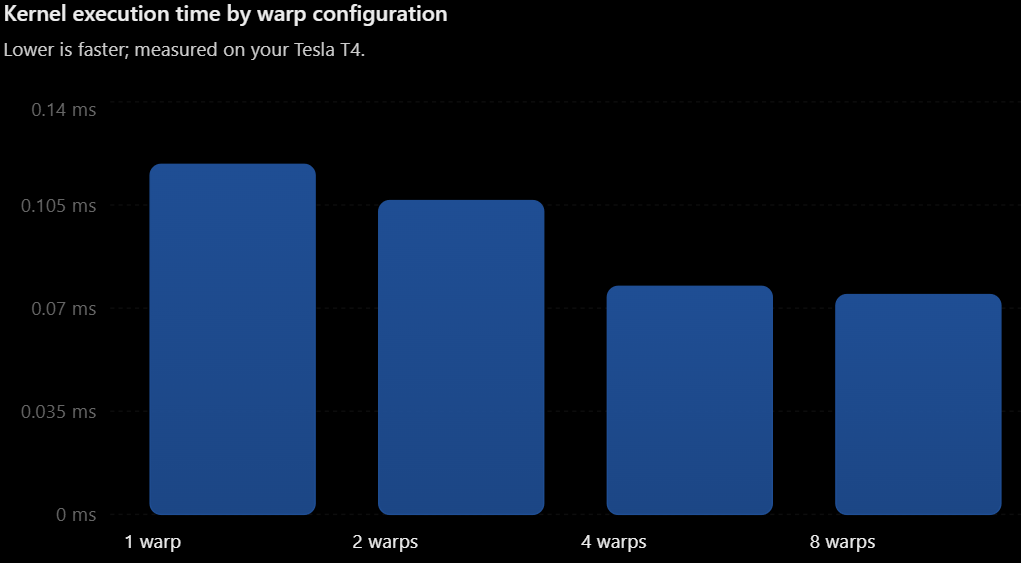

# Experiment 5: Warp Configuration and Register Usage

## 1. Objective

The objective of this experiment is to understand how the number of warps per block affects GPU execution performance and compiler-reported resource usage.

We compare four configurations: 1, 2, 4, and 8 warps per block.

We investigate:
- Threads per block.
- Registers used per thread.
- Shared-memory usage.
- Register spills.
- Kernel execution time.

The experiment uses a custom Triton kernel on an NVIDIA Tesla T4 GPU.

## 2. Hardware and workload

| Parameter | Value |
|---|---|
| GPU | NVIDIA Tesla T4 |
| SM count | 40 |
| Total elements | 1,048,576 |
| Elements per block | 1,024 |
| Arithmetic iterations | 128 |
| Warp size | 32 threads |
| Warp configurations | 1, 2, 4, 8 |

The block size and arithmetic workload remain constant while the number of warps changes.

## 3. Important concepts

### Warp

A warp is a group of 32 threads that execute instructions together on NVIDIA GPUs.

### Threads per block

The number of threads in a block is determined by:

`Threads per block = Warps per block × 32`

### Registers

Registers are small, fast storage locations used by individual threads to hold temporary values and intermediate computation results.

The register file is a limited hardware resource within each SM. Higher register consumption per thread can reduce the number of threads that can reside simultaneously on an SM.

### Shared memory

Shared memory is a fast, explicitly managed memory space shared by threads within the same block.

### Register spilling

Register spilling occurs when the compiler cannot keep all required values in registers and places some values in local memory instead. This can introduce additional memory traffic.

### Latency hiding

Latency hiding is the ability of the GPU to execute instructions from other eligible warps while some warps are waiting for memory or other operations.

## 4. Experimental results

| Warps | Threads/block | Registers/thread | Shared memory (bytes) | Spills | Time (ms) |
|---:|---:|---:|---:|---:|---:|
| 1 | 32 | 72 | 0 | 0 | 0.1188 |
| 2 | 64 | 34 | 0 | 0 | 0.1065 |
| 4 | 128 | 24 | 0 | 0 | 0.0774 |
| 8 | 256 | 16 | 0 | 0 | 0.0746 |

## 5. Observations

1. Increasing the number of warps increases the number of threads per block.
2. The reported register usage per thread decreases from 72 registers with one warp to 16 registers with eight warps.
3. Shared-memory usage is zero for all configurations because the kernel does not require shared-memory allocation.
4. No register spills were reported in any configuration.
5. Kernel execution time decreases as the number of warps increases in this experiment.
6. The eight-warp configuration achieves the lowest measured execution time.

## 6. Performance analysis

The one-warp configuration takes 0.1188 ms, while the eight-warp configuration takes 0.0746 ms.

Percentage reduction in execution time:

`((0.1188 - 0.0746) / 0.1188) × 100`

**Result: approximately 37.2% reduction.**

The eight-warp configuration is approximately 1.59 times as fast as the one-warp configuration for this workload.

The improvement from four to eight warps is relatively small (approximately 3.6%), suggesting diminishing performance benefits as the warp count increases.

## 7. Conclusion

This experiment demonstrates that warp configuration and register allocation can influence GPU kernel performance.

Increasing the number of warps per block changes how the workload is distributed among threads. In this experiment, configurations with more warps used fewer reported registers per thread and achieved lower execution times.

However, the experiment does not directly measure achieved occupancy or SM utilization. The best warp configuration depends on the kernel's computation, memory access patterns, and hardware resource requirements.

**For this particular Tesla T4 workload, eight warps per block produced the best measured execution time.**

## 8. Limitations

- Execution times can vary due to GPU load and benchmarking conditions.
- Compiler-reported register counts are not direct occupancy measurements.
- Zero reported spills does not establish that all possible memory bottlenecks are absent.
- The experiment does not directly observe warp scheduler decisions.
- The finite-value check is a sanity check, not a complete numerical correctness test.


# GPU Memory Hierarchy

In [11]:

import torch
import triton
import triton.language as tl

print("=" * 75)
print("EXPERIMENT 6: GPU MEMORY HIERARCHY")
print("=" * 75)

@triton.jit
def memory_kernel(X, Y, N: tl.constexpr,
                  BLOCK_SIZE: tl.constexpr,
                  CACHE: tl.constexpr):

    pid = tl.program_id(0)
    offsets = pid * BLOCK_SIZE + tl.arange(0, BLOCK_SIZE)
    mask = offsets < N

    x = tl.load(
        X + offsets,
        mask=mask,
        other=0.0,
        cache_modifier=CACHE
    )

    tl.store(Y + offsets, x, mask=mask)


device = "cuda:0"
BLOCK_SIZE = 1024

sizes_mb = [0.25, 1, 4, 16, 64]
cache_modes = [".ca", ".cg"]

print("GPU:", torch.cuda.get_device_name(0))
print("Block size:", BLOCK_SIZE)

print("\n")
print(
    f"{'Size(MB)':<12}"
    f"{'Cache Mode':<15}"
    f"{'Time(ms)':<15}"
    f"{'Bandwidth(GB/s)':<18}"
)
print("-" * 60)

results = []

for size_mb in sizes_mb:

    n = int(size_mb * 1024 * 1024 / 4)

    X = torch.randn(n, device=device)
    Y = torch.empty_like(X)

    grid = (triton.cdiv(n, BLOCK_SIZE),)

    for cache in cache_modes:

        # Compile and warm up
        memory_kernel.warmup(
            X, Y, n, BLOCK_SIZE, cache,
            grid=grid
        )

        # Warm-up execution
        for _ in range(5):
            memory_kernel[grid](
                X, Y, n, BLOCK_SIZE, cache
            )

        torch.cuda.synchronize()

        # Benchmark
        latency_ms = triton.testing.do_bench(
            lambda: memory_kernel[grid](
                X, Y, n, BLOCK_SIZE, cache
            )
        )

        # One read + one write per element
        total_bytes = n * 4 * 2
        bandwidth_gbs = (
            total_bytes / (latency_ms / 1000) / 1e9
        )

        results.append(
            (size_mb, cache, latency_ms, bandwidth_gbs)
        )

        print(
            f"{size_mb:<12.2f}"
            f"{cache:<15}"
            f"{latency_ms:<15.4f}"
            f"{bandwidth_gbs:<18.2f}"
        )

    del X, Y

print("\n" + "=" * 75)
print("EXPERIMENT 6 COMPLETED")
print("=" * 75)


EXPERIMENT 6: GPU MEMORY HIERARCHY
GPU: Tesla T4
Block size: 1024


Size(MB)    Cache Mode     Time(ms)       Bandwidth(GB/s)   
------------------------------------------------------------
0.25        .ca            0.0084         62.13             
0.25        .cg            0.0079         65.95             
1.00        .ca            0.0118         178.40            
1.00        .cg            0.0117         179.22            
4.00        .ca            0.0387         216.49            
4.00        .cg            0.0386         217.24            
16.00       .ca            0.1488         225.49            
16.00       .cg            0.1487         225.61            
64.00       .ca            0.5853         229.33            
64.00       .cg            0.5854         229.26            

EXPERIMENT 6 COMPLETED


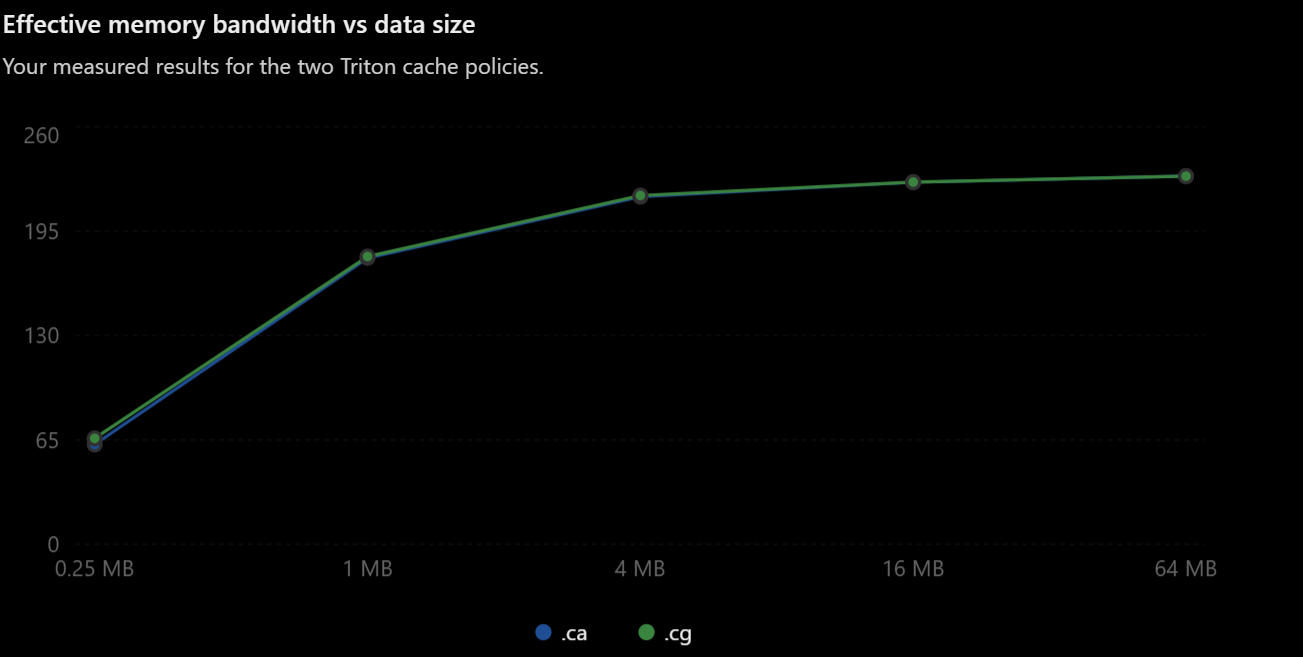

# Experiment 6: GPU Memory Hierarchy and Cache Behaviour

## 1. Objective

To investigate GPU memory performance by changing the input data size and comparing two global-memory load cache policies using Triton.

The experiment examines:
- Global memory access.
- L1 cache policy.
- L2 cache behaviour.
- Effective memory bandwidth.
- The influence of workload size on measured throughput.

## 2. Hardware

| Parameter | Value |
|---|---|
| GPU | NVIDIA Tesla T4 |
| GPU architecture | Turing |
| Number of SMs | 40 |
| Framework | PyTorch |
| Kernel language | Triton |
| Block size | 1,024 elements |

## 3. Memory hierarchy

The GPU memory hierarchy consists of:

1. Registers: Fast storage used by individual threads.
2. Shared memory: On-chip memory shared by threads within a block.
3. L1 cache: A small cache associated with an SM.
4. L2 cache: A larger cache shared across SMs.
5. Global memory: GPU VRAM with high capacity.

Smaller, closer memory generally provides lower access latency, while larger memory provides greater capacity.

## 4. Cache policies

Two Triton cache modifiers were tested:

- `.ca`: Cache at all applicable levels, including L1.
- `.cg`: Cache globally, bypassing L1 for these loads.

Both policies can still use L2 caching.

## 5. Experimental results

| Input size (MiB) | Cache policy | Time (ms) | Effective bandwidth (GB/s) |
|---:|---|---:|---:|
| 0.25 | .ca | 0.0084 | 62.13 |
| 0.25 | .cg | 0.0079 | 65.95 |
| 1 | .ca | 0.0118 | 178.40 |
| 1 | .cg | 0.0117 | 179.22 |
| 4 | .ca | 0.0387 | 216.49 |
| 4 | .cg | 0.0386 | 217.24 |
| 16 | .ca | 0.1488 | 225.49 |
| 16 | .cg | 0.1487 | 225.61 |
| 64 | .ca | 0.5853 | 229.33 |
| 64 | .cg | 0.5854 | 229.26 |

## 6. Bandwidth calculation

Each element uses the FP32 data type, occupying 4 bytes.

The kernel reads one input element and writes one output element.

Therefore:

`Total logical bytes = Number of elements × 4 × 2`

Effective bandwidth is calculated as:

`Bandwidth = Total logical bytes / Execution time`

The reported bandwidth is based on logical read and write traffic, not direct physical DRAM traffic.

## 7. Observations

1. Effective bandwidth increases as the workload size increases.
2. The smallest workload achieves approximately 62–66 GB/s.
3. The 1 MiB workload achieves approximately 178–179 GB/s.
4. The larger workloads reach approximately 216–229 GB/s.
5. The `.ca` and `.cg` policies produce very similar results.
6. The 64 MiB workload achieves the highest measured bandwidth: approximately 229 GB/s.

## 8. Analysis

For small workloads, kernel launch overhead and measurement overhead have a larger influence on the measured execution time.

As the workload grows, these fixed costs become less significant, allowing the GPU to sustain higher effective bandwidth.

The similar performance of `.ca` and `.cg` suggests that changing the L1 load-cache policy did not significantly affect this particular workload.

The kernel reads each input element once and writes each output element once. It does not intentionally perform repeated accesses to the same input values within a kernel invocation.

## 9. Conclusion

This experiment demonstrates that effective GPU memory bandwidth depends on workload size and access behaviour.

The Tesla T4 achieved approximately 229 GB/s of effective logical bandwidth in the largest test.

The two cache policies performed almost identically, showing that bypassing L1 did not produce a meaningful performance difference for this workload.

The experiment provides an indirect view of cache behaviour. It does not directly measure L1/L2 cache hit rates, physical DRAM bandwidth or memory access latency.

**Key learning:** GPU performance depends not only on computation but also on how efficiently data moves through the memory hierarchy.

## 10. Limitations

- Cache hit rates were not directly measured.
- Physical DRAM traffic was not measured.
- Kernel launch overhead affects small workloads.
- Benchmark results can vary with GPU load.
- The experiment does not isolate individual L1 and L2 latency.


# Memory Coalescing

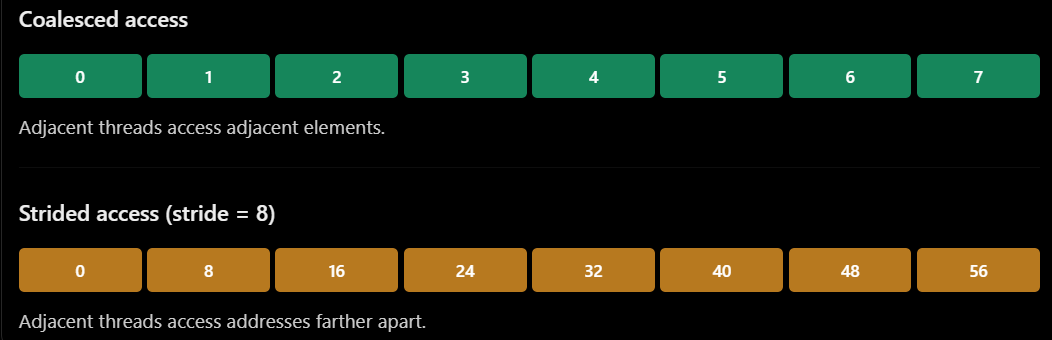

In [12]:

import torch
import triton
import triton.language as tl

print("=" * 70)
print("EXPERIMENT 7: MEMORY COALESCING")
print("=" * 70)

@triton.jit
def coalesced_kernel(X, Y, N: tl.constexpr,
                     BLOCK: tl.constexpr):
    pid = tl.program_id(0)
    offsets = pid * BLOCK + tl.arange(0, BLOCK)
    x = tl.load(X + offsets, offsets < N, other=0)
    tl.store(Y + offsets, x + 1, offsets < N)


@triton.jit
def strided_kernel(X, Y, N: tl.constexpr,
                   BLOCK: tl.constexpr,
                   STRIDE: tl.constexpr):
    pid = tl.program_id(0)
    offsets = pid * BLOCK + tl.arange(0, BLOCK)
    x = tl.load(X + offsets * STRIDE,
                offsets < N, other=0)
    tl.store(Y + offsets, x + 1, offsets < N)


device = "cuda:0"
N = 1 << 22
BLOCK = 1024

X = torch.randn(N * 8, device=device)
Y = torch.empty(N, device=device)

print("GPU:", torch.cuda.get_device_name(0))
print("Elements processed:", N)

print("\nAccess Pattern       Time(ms)       Bandwidth(GB/s)")
print("-" * 55)

for stride, name in [(1, "Coalesced"), (8, "Strided-8")]:
    grid = (triton.cdiv(N, BLOCK),)

    if stride == 1:
        fn = lambda: coalesced_kernel[grid](
            X, Y, N, BLOCK
        )
    else:
        fn = lambda: strided_kernel[grid](
            X, Y, N, BLOCK, stride
        )

    fn()
    torch.cuda.synchronize()

    ms = triton.testing.do_bench(fn)

    # Logical bytes read + written
    read_bytes = N * 4
    write_bytes = N * 4
    logical_gbs = (
        (read_bytes + write_bytes) / (ms / 1000) / 1e9
    )

    print(f"{name:<21}{ms:<15.4f}{logical_gbs:.2f}")

print("\nOutput finite:", torch.isfinite(Y).all().item())
print("EXPERIMENT 7 COMPLETED")


EXPERIMENT 7: MEMORY COALESCING
GPU: Tesla T4
Elements processed: 4194304

Access Pattern       Time(ms)       Bandwidth(GB/s)
-------------------------------------------------------
Coalesced            0.1457         230.36
Strided-8            0.6559         51.16

Output finite: True
EXPERIMENT 7 COMPLETED


# Experiment 7: GPU Memory Coalescing

## Objective

To understand how memory access patterns affect GPU performance by comparing consecutive and strided memory accesses using Triton.

## Hardware

- GPU: NVIDIA Tesla T4
- Framework: PyTorch
- Kernel language: Triton
- Elements processed: 4,194,304
- Block size: 1,024 elements
- Data type: FP32

## Concepts

**Memory coalescing:** Combining neighbouring threads' memory requests into fewer efficient memory transactions.

**Coalesced access:** Threads access consecutive memory addresses.

**Strided access:** Threads access addresses separated by a fixed distance.

## Experimental results

| Access pattern | Execution time (ms) | Effective bandwidth (GB/s) |
|---|---:|---:|
| Coalesced | 0.1457 | 230.36 |
| Strided-8 | 0.6559 | 51.16 |

## Observations

1. Coalesced memory access achieved 230.36 GB/s effective bandwidth.
2. Strided-8 memory access achieved 51.16 GB/s.
3. The coalesced kernel completed execution in 0.1457 ms.
4. The strided kernel required 0.6559 ms.
5. Both kernels processed the same number of output elements.
6. The output contained only finite values.

## Performance analysis

Speedup:

`0.6559 / 0.1457 ≈ 4.50`

The coalesced kernel was approximately 4.5 times faster than the strided kernel.

The difference occurs because consecutive memory accesses allow neighbouring threads to use memory transactions more efficiently.

Strided access spreads requests across memory locations and can increase transaction overhead.

## Conclusion

This experiment demonstrates that memory access patterns significantly influence GPU performance.

Coalesced memory access improves effective bandwidth and reduces execution time.

**Key learning:** To achieve good GPU performance, neighbouring threads should access neighbouring memory locations whenever the workload permits.

## Limitations

- Effective bandwidth is calculated using logical read and write bytes.
- Actual physical memory transactions were not directly measured.
- Cache behaviour can influence measured performance.
- The benchmark does not directly report memory transaction counts.


# Shared Memory Optimization

In [13]:

import torch
import triton
import triton.language as tl

print("=" * 70)
print("EXPERIMENT 8: TILED MATRIX MULTIPLICATION")
print("=" * 70)

@triton.jit
def matmul_kernel(
    A, B, C,
    M: tl.constexpr,
    N: tl.constexpr,
    K: tl.constexpr,
    BM: tl.constexpr,
    BN: tl.constexpr,
    BK: tl.constexpr
):
    pid_m = tl.program_id(0)
    pid_n = tl.program_id(1)

    rows = pid_m * BM + tl.arange(0, BM)
    cols = pid_n * BN + tl.arange(0, BN)
    ks = tl.arange(0, BK)

    acc = tl.zeros((BM, BN), dtype=tl.float32)

    for k in range(triton.cdiv(K, BK)):
        k_offsets = k * BK + ks

        a = tl.load(
            A + rows[:, None] * K + k_offsets[None, :],
            (rows[:, None] < M) &
            (k_offsets[None, :] < K),
            other=0
        )

        b = tl.load(
            B + k_offsets[:, None] * N + cols[None, :],
            (k_offsets[:, None] < K) &
            (cols[None, :] < N),
            other=0
        )

        acc += tl.dot(a, b)

    tl.store(
        C + rows[:, None] * N + cols[None, :],
        acc,
        (rows[:, None] < M) &
        (cols[None, :] < N)
    )


device = "cuda:0"
M = N = K = 1024

A = torch.randn((M, K), device=device, dtype=torch.float32)
B = torch.randn((K, N), device=device, dtype=torch.float32)
C = torch.empty((M, N), device=device)

configs = [
    (16, 32, 32, 4),
    (32, 32, 32, 4),
    (32, 64, 32, 4),
    (32, 64, 64, 4),
]

print("GPU:", torch.cuda.get_device_name(0))
print("Matrix dimensions:", M, "x", N, "x", K)

print("\nBM BN BK Warps Time(ms) TFLOPS SharedMem")
print("-" * 60)

for BM, BN, BK, warps in configs:
    grid = (triton.cdiv(M, BM), triton.cdiv(N, BN))

    fn = lambda: matmul_kernel[grid](
        A, B, C, M, N, K, BM, BN, BK,
        num_warps=warps
    )

    compiled = matmul_kernel.warmup(
        A, B, C, M, N, K, BM, BN, BK,
        grid=grid,
        num_warps=warps
    )

    fn()
    torch.cuda.synchronize()

    ms = triton.testing.do_bench(fn)

    operations = 2 * M * N * K
    tflops = operations / (ms / 1000) / 1e12

    print(
        f"{BM:<3} {BN:<3} {BK:<3} {warps:<5} "
        f"{ms:<8.4f} {tflops:<8.3f} "
        f"{compiled.metadata.shared}"
    )

reference = A @ B
print("\nCorrectness:", torch.allclose(C, reference, rtol=1e-2, atol=1e-2))
print("Experiment 8 completed")


EXPERIMENT 8: TILED MATRIX MULTIPLICATION
GPU: Tesla T4
Matrix dimensions: 1024 x 1024 x 1024

BM BN BK Warps Time(ms) TFLOPS SharedMem
------------------------------------------------------------
16  32  32  4     2.8254   0.760    6144
32  32  32  4     1.2980   1.654    8192
32  64  32  4     0.9755   2.201    12288
32  64  64  4     1.0472   2.051    24576

Correctness: True
Experiment 8 completed


# Experiment 8: Shared Memory Optimization Using Tiled Matrix Multiplication

## 1. Objective

To understand how tiled matrix multiplication improves GPU computation through data reuse and efficient memory management.

The experiment compares four tile configurations on an NVIDIA Tesla T4 using Triton.

## 2. Hardware and workload

| Parameter | Value |
|---|---|
| GPU | NVIDIA Tesla T4 |
| Matrix A | 1024 × 1024 |
| Matrix B | 1024 × 1024 |
| Output matrix C | 1024 × 1024 |
| Framework | PyTorch |
| Kernel language | Triton |
| Warps per block | 4 |

## 3. Important concepts

- **Tiling:** Dividing large matrix computations into smaller blocks.
- **BM:** Number of output rows processed per tile.
- **BN:** Number of output columns processed per tile.
- **BK:** Reduction dimension processed per iteration.
- **Shared memory:** Fast on-chip memory used for data sharing and reuse within a block.
- **TFLOPS:** Trillions of floating-point operations per second.

Tiled computation improves data reuse and can reduce repeated global-memory accesses.

## 4. Experimental results

| BM | BN | BK | Time (ms) | TFLOPS | Shared memory (bytes) |
|---:|---:|---:|---:|---:|---:|
| 16 | 32 | 32 | 2.8254 | 0.760 | 6144 |
| 32 | 32 | 32 | 1.2980 | 1.654 | 8192 |
| 32 | 64 | 32 | 0.9755 | 2.201 | 12288 |
| 32 | 64 | 64 | 1.0472 | 2.051 | 24576 |

## 5. Observations

1. Increasing BM from 16 to 32 improved performance.
2. Increasing BN from 32 to 64 further improved performance.
3. Increasing BK from 32 to 64 increased shared-memory usage.
4. The configuration with BM=32, BN=64 and BK=32 achieved the highest measured throughput.
5. The largest shared-memory allocation did not produce the best performance.
6. The numerical correctness test passed.

## 6. Performance analysis

The best configuration achieved:

- Execution time: 0.9755 ms.
- Throughput: 2.201 TFLOPS.
- Shared-memory allocation: 12,288 bytes.

The slowest configuration achieved 0.760 TFLOPS.

The best configuration was approximately 2.9 times as fast as the slowest configuration.

Increasing tile dimensions can improve data reuse, but larger tiles can also consume more hardware resources.

Therefore, tile dimensions must be tuned according to the workload and GPU architecture.

## 7. Conclusion

This experiment demonstrates how tiled matrix multiplication can improve GPU computation through efficient data reuse.

It also demonstrates that shared-memory allocation and tile size influence performance.

The best configuration in this experiment was BM=32, BN=64 and BK=32 with four warps.

The compiler reported shared-memory allocation even though the kernel did not explicitly manage shared memory.

**Key learning:** Efficient GPU programming requires balancing data reuse, tile dimensions and hardware resource consumption.

## 8. Limitations

- The experiment compares only four tile configurations.
- Shared-memory usage is compiler-reported metadata.
- It does not directly measure shared-memory bandwidth.
- Performance can vary with GPU load and compiler behaviour.
- The result is specific to this matrix size and Tesla T4 environment.


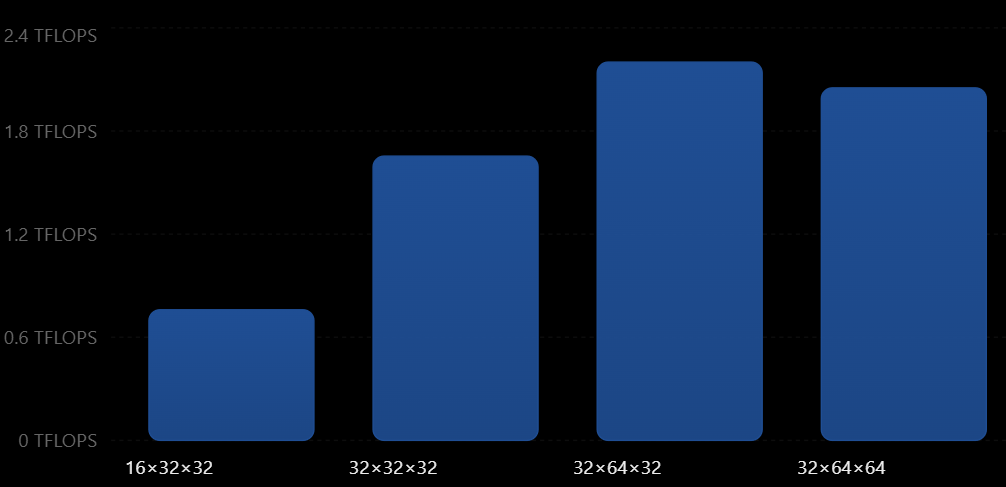

# CUDA Cores and Compute Throughput

In [14]:

import torch
import triton
import triton.language as tl

print("=" * 70)
print("EXPERIMENT 9: CUDA CORES AND COMPUTE THROUGHPUT")
print("=" * 70)

@triton.jit
def compute_kernel(X, Y, N: tl.constexpr,
                   BLOCK: tl.constexpr,
                   ITERS: tl.constexpr):

    pid = tl.program_id(0)
    offsets = pid * BLOCK + tl.arange(0, BLOCK)
    mask = offsets < N

    x = tl.load(X + offsets, mask, other=1.0)

    for i in range(ITERS):
        x = x * 1.0001 + 0.0001

    tl.store(Y + offsets, x, mask)


device = "cuda:0"
N = 1 << 22
BLOCK = 1024

X = torch.randn(N, device=device)
Y = torch.empty_like(X)

print("GPU:", torch.cuda.get_device_name(0))
print("Elements:", N)

print("\nIterations  Time(ms)  Estimated GFLOPS")
print("-" * 50)

for iters in [1, 10, 50, 100, 200, 500]:

    grid = (triton.cdiv(N, BLOCK),)

    fn = lambda: compute_kernel[grid](
        X, Y, N, BLOCK, iters
    )

    fn()
    torch.cuda.synchronize()

    ms = triton.testing.do_bench(fn)

    # Approx. 2 floating-point operations per iteration per element
    flops = N * iters * 2
    gflops = flops / (ms / 1000) / 1e9

    print(f"{iters:<12}{ms:<10.4f}{gflops:.2f}")

print("\nOutput finite:", torch.isfinite(Y).all().item())
print("EXPERIMENT 9 COMPLETED")


EXPERIMENT 9: CUDA CORES AND COMPUTE THROUGHPUT
GPU: Tesla T4
Elements: 4194304

Iterations  Time(ms)  Estimated GFLOPS
--------------------------------------------------
1           0.1458    57.55
10          0.1459    574.96
50          0.1488    2818.51
100         0.1504    5576.89
200         0.2279    7363.04
500         0.5798    7234.16

Output finite: True
EXPERIMENT 9 COMPLETED


# Tensor Cores

In [15]:

import torch
import triton
import triton.language as tl

print("=" * 65)
print("EXPERIMENT 10: TENSOR CORE PERFORMANCE")
print("=" * 65)

device = "cuda:0"
M = N = K = 2048

A = torch.randn((M, K), device=device)
B = torch.randn((K, N), device=device)

def benchmark(fn):
    fn()
    torch.cuda.synchronize()
    return triton.testing.do_bench(fn)

print("GPU:", torch.cuda.get_device_name(0))
print("\nPrecision     Time(ms)    TFLOPS")
print("-" * 45)

results = {}

# FP32 standard CUDA matrix multiplication
def fp32():
    return torch.mm(A, B)

ms = benchmark(fp32)
results["FP32"] = ms
print(f"{'FP32':<14}{ms:<12.4f}{(2*M*N*K/(ms/1000)/1e12):.3f}")

# TF32 Tensor Core computation
torch.backends.cuda.matmul.allow_tf32 = True

def tf32():
    return torch.mm(A, B)

ms = benchmark(tf32)
results["TF32"] = ms
print(f"{'TF32':<14}{ms:<12.4f}{(2*M*N*K/(ms/1000)/1e12):.3f}")

# FP16 Tensor Core computation
A16 = A.half()
B16 = B.half()

def fp16():
    return torch.mm(A16, B16)

ms = benchmark(fp16)
results["FP16"] = ms
print(f"{'FP16':<14}{ms:<12.4f}{(2*M*N*K/(ms/1000)/1e12):.3f}")

print("\nFP16 output finite:", torch.isfinite(fp16()).all().item())
print("EXPERIMENT 10 COMPLETED")


EXPERIMENT 10: TENSOR CORE PERFORMANCE
GPU: Tesla T4

Precision     Time(ms)    TFLOPS
---------------------------------------------
FP32          6.0275      2.850
TF32          4.1093      4.181
FP16          0.4868      35.293

FP16 output finite: True
EXPERIMENT 10 COMPLETED


# Experiment 10: Tensor Core Performance

## Objective
Compare FP32, TF32-enabled PyTorch matrix multiplication and FP16 matrix multiplication on an NVIDIA Tesla T4.

## Workload
- GPU: Tesla T4
- Matrix dimensions: 2048 × 2048
- Framework: PyTorch
- Operation: Matrix multiplication

## Results

| Precision | Execution time (ms) | Estimated throughput (TFLOPS) |
|---|---:|---:|
| FP32 | 6.0275 | 2.850 |
| TF32-enabled | 4.1093 | 4.181 |
| FP16 | 0.4868 | 35.293 |

## Observations
1. FP32 achieved 2.850 TFLOPS.
2. The TF32-enabled benchmark achieved 4.181 TFLOPS.
3. FP16 achieved 35.293 TFLOPS.
4. FP16 was approximately 12.4 times faster than FP32.
5. The FP16 output contained finite values.

## Conclusion
FP16 matrix multiplication achieved the highest measured throughput.

The Tesla T4 supports FP16 Tensor Core acceleration, making reduced-precision matrix multiplication especially useful for deep-learning workloads.

The T4 does not natively support TF32 Tensor Core operations. Therefore, the TF32-enabled result should not be interpreted as a native TF32 Tensor Core measurement.

The experiment demonstrates the importance of numerical precision and specialized hardware in accelerating neural-network computations.

## Limitations
- Results are specific to the tested matrix size and GPU.
- The benchmark does not directly inspect hardware instruction execution.
- Numerical accuracy was not comprehensively compared across all precisions.
- The TF32-enabled setting does not establish native TF32 Tensor Core use on T4.


# Occupancy and GPU Utilization

In [16]:

import torch
import triton
import triton.language as tl

@triton.jit
def occupancy_kernel(X, Y, N: tl.constexpr,
                     BLOCK: tl.constexpr):
    pid = tl.program_id(0)
    offsets = pid * BLOCK + tl.arange(0, BLOCK)
    mask = offsets < N

    x = tl.load(X + offsets, mask, other=0)
    for _ in range(100):
        x = x * 1.0001 + 0.0001
    tl.store(Y + offsets, x, mask)

device = "cuda:0"
N = 1 << 24
X = torch.randn(N, device=device)
Y = torch.empty_like(X)

print("GPU:", torch.cuda.get_device_name(0))
print("\nBlock size | Warps | Time(ms)")

for block in [256, 512, 1024, 2048]:
    for warps in [4, 8]:
        grid = (triton.cdiv(N, block),)
        fn = lambda: occupancy_kernel[grid](
            X, Y, N, block, num_warps=warps
        )
        ms = triton.testing.do_bench(fn)
        print(f"{block:<10} | {warps:<5} | {ms:.4f}")

print("Completed")


GPU: Tesla T4

Block size | Warps | Time(ms)
256        | 4     | 1.0962
256        | 8     | 0.9998
512        | 4     | 0.5561
512        | 8     | 0.5440
1024       | 4     | 0.5732
1024       | 8     | 0.5529
2048       | 4     | 0.5864
2048       | 8     | 0.5649
Completed


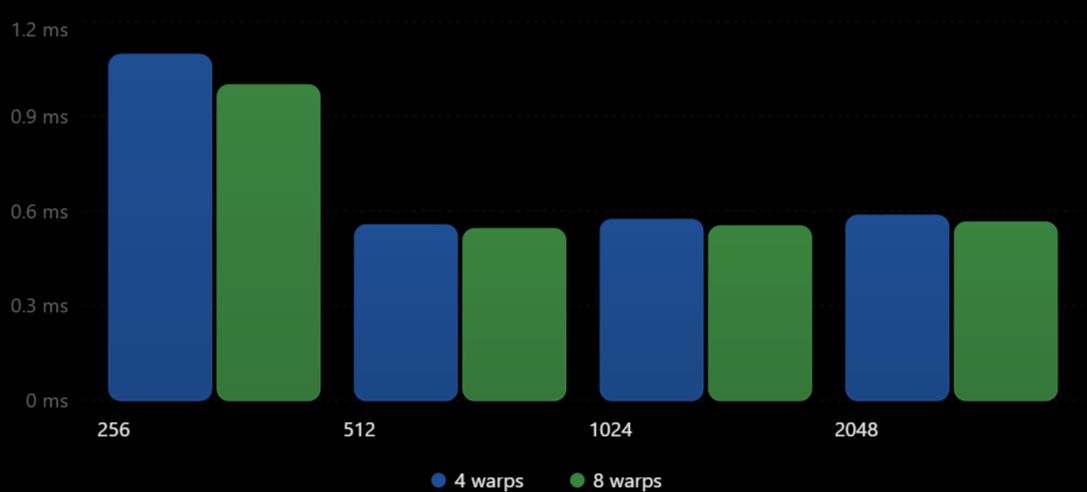

# Experiment 11: Occupancy and GPU Performance

## Objective
Investigate how block size and warp configuration affect GPU kernel execution time on an NVIDIA Tesla T4.

## Hardware
- GPU: NVIDIA Tesla T4
- Input elements: 16,777,216
- Framework: PyTorch
- Kernel language: Triton

## Results

| Block size | Warps | Execution time (ms) |
|---:|---:|---:|
| 256 | 4 | 1.0962 |
| 256 | 8 | 0.9998 |
| 512 | 4 | 0.5561 |
| 512 | 8 | 0.5440 |
| 1024 | 4 | 0.5732 |
| 1024 | 8 | 0.5529 |
| 2048 | 4 | 0.5864 |
| 2048 | 8 | 0.5649 |

## Observations
1. The 512-element block configuration achieved the lowest execution time.
2. Eight warps performed better than four warps in every tested configuration.
3. Block size 256 produced the highest execution times.
4. Increasing block size beyond 512 did not improve performance.

## Conclusion
Block size and warp configuration influence GPU kernel performance.

The best tested configuration was 512 elements per block with eight warps, achieving 0.5440 ms.

This experiment measures execution time rather than achieved occupancy. Direct occupancy and GPU utilization measurements require additional profiling tools or hardware counters.

**Key learning:** Optimal GPU performance requires balancing block size, warp count and hardware resource consumption.


# Resnet

In [17]:

import torch
import torchvision
import torchvision.transforms as T
import torch.nn as nn
import torch.optim as optim
import time
import numpy as np

from torch.utils.data import DataLoader, Subset
from torchvision.models import resnet50

print("=" * 70)
print("EXPERIMENT 12: RESNET-50 GPU TRAINING")
print("=" * 70)

device = "cuda"

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

# 1. Dataset
transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

val_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_data = Subset(train_data, range(10000))
val_data = Subset(val_data, range(2000))

train_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# 2. Model
model = resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 10)

model = model.to(device, memory_format=torch.channels_last)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001)

scaler = torch.amp.GradScaler("cuda")

torch.cuda.reset_peak_memory_stats()

print("\nModel: ResNet-50")
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Batch size:", 64)

# 3. Training
model.train()
running_loss = 0
correct = 0
total = 0

start = time.time()

for batch_idx, (images, labels) in enumerate(train_loader):

    images = images.to(
        device, non_blocking=True,
        memory_format=torch.channels_last
    )
    labels = labels.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        outputs = model(images)
        loss = criterion(outputs, labels)

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    running_loss += loss.item()
    predicted = outputs.argmax(dim=1)

    total += labels.size(0)
    correct += (predicted == labels).sum().item()

    if (batch_idx + 1) % 20 == 0:
        print(
            f"Step {batch_idx+1}/{len(train_loader)} | "
            f"Loss: {loss.item():.4f}"
        )

torch.cuda.synchronize()
train_time = time.time() - start

train_accuracy = 100 * correct / total
avg_loss = running_loss / len(train_loader)

# 4. Validation
model.eval()
val_correct = 0
val_total = 0

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(
            device, non_blocking=True,
            memory_format=torch.channels_last
        )
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)

        val_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()

        val_total += labels.size(0)

val_accuracy = 100 * val_correct / val_total

# 5. Performance metrics
peak_memory = torch.cuda.max_memory_allocated() / (1024**3)
throughput = len(train_data) / train_time

print("\n" + "=" * 70)
print("RESNET-50 TRAINING RESULTS")
print("=" * 70)

print(f"Training time: {train_time:.2f} seconds")
print(f"Average loss: {avg_loss:.4f}")
print(f"Training accuracy: {train_accuracy:.2f}%")
print(f"Validation accuracy: {val_accuracy:.2f}%")
print(f"Throughput: {throughput:.2f} images/sec")
print(f"Peak GPU memory: {peak_memory:.2f} GB")

print("\nGPU memory allocated:",
      torch.cuda.memory_allocated() / 1024**3, "GB")

print("EXPERIMENT 12 COMPLETED")


EXPERIMENT 12: RESNET-50 GPU TRAINING
GPU: Tesla T4
PyTorch: 2.11.0+cu130


100%|██████████| 170M/170M [05:19<00:00, 533kB/s] 



Model: ResNet-50
Parameters: 23528522
Training images: 10000
Validation images: 2000
Batch size: 64
Step 20/157 | Loss: 2.1700
Step 40/157 | Loss: 1.8407
Step 60/157 | Loss: 2.0496
Step 80/157 | Loss: 2.0601
Step 100/157 | Loss: 1.8575
Step 120/157 | Loss: 1.9049
Step 140/157 | Loss: 1.6552

RESNET-50 TRAINING RESULTS
Training time: 43.93 seconds
Average loss: 2.0294
Training accuracy: 27.36%
Validation accuracy: 33.45%
Throughput: 227.62 images/sec
Peak GPU memory: 3.20 GB

GPU memory allocated: 0.5738725662231445 GB
EXPERIMENT 12 COMPLETED


# Experiment 12: ResNet-50 Training on NVIDIA Tesla T4

## Objective
Train a ResNet-50 convolutional neural network using GPU acceleration and evaluate training performance.

## Environment

- GPU: NVIDIA Tesla T4
- Framework: PyTorch
- Model: ResNet-50
- Dataset: CIFAR-10
- Training subset: 10,000 images
- Validation subset: 2,000 images
- Input resolution: 224 × 224
- Batch size: 64
- Precision: FP16 mixed precision
- Optimizer: AdamW

## Model information

Total parameters: 23,528,522

The final fully connected layer was modified for 10 CIFAR-10 classes.

## Results

| Metric | Result |
|---|---:|
| Training time | 43.93 seconds |
| Average training loss | 2.0294 |
| Training accuracy | 27.36% |
| Validation accuracy | 33.45% |
| Throughput | 227.62 images/second |
| Peak GPU memory | 3.20 GB |

## Observations

1. ResNet-50 successfully trained on the Tesla T4.
2. Mixed-precision training completed without reported errors.
3. Training processed 10,000 images in 43.93 seconds.
4. The measured throughput was 227.62 images per second.
5. Peak allocated GPU memory was 3.20 GB.
6. Validation accuracy was 33.45% after one epoch.

## Conclusion

This experiment demonstrates real-world GPU-accelerated deep-learning training.

It combines GPU computation, memory transfers, mixed precision, matrix operations and neural-network optimization.

The results establish a baseline for subsequent profiling and performance optimization.

One epoch is not sufficient to evaluate final model accuracy or convergence.

**Key learning:** GPU architecture concepts become practically relevant when training real neural networks.


In [18]:

!nvidia-smi

import torch

print("\nCUDA Memory Summary")
print(torch.cuda.memory_summary(device=0, abbreviated=True))

print("\nGPU Properties")
p = torch.cuda.get_device_properties(0)

print("GPU:", p.name)
print("SM count:", p.multi_processor_count)
print("Total memory (GB):", round(p.total_memory / 1024**3, 2))


Sat Nov 14 07:06:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   71C    P0             30W /   70W |    3729MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [19]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import time
import copy

from torch.utils.data import DataLoader
from torchvision.models import resnet50

print("=" * 75)
print("FINAL EXPERIMENT: ORDINARY VS GPU-OPTIMIZED TRAINING")
print("=" * 75)

device = "cuda"
BATCH_SIZE = 64
EPOCHS = 2

# Same initial model weights for both approaches
torch.manual_seed(42)

base_model = resnet50(weights=None)
base_model.fc = nn.Linear(base_model.fc.in_features, 10)

initial_weights = copy.deepcopy(base_model.state_dict())
del base_model

def train_experiment(optimized):

    name = "GPU-OPTIMIZED" if optimized else "ORDINARY"

    print(f"\nStarting {name} training...")

    torch.manual_seed(42)

    loader = DataLoader(
        train_data,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2 if optimized else 0,
        pin_memory=optimized
    )

    val_loader = DataLoader(
        val_data,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2 if optimized else 0,
        pin_memory=optimized
    )

    model = resnet50(weights=None)
    model.fc = nn.Linear(model.fc.in_features, 10)
    model.load_state_dict(initial_weights)

    if optimized:
        model = model.to(
            device,
            memory_format=torch.channels_last
        )
    else:
        model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=0.001)

    scaler = torch.amp.GradScaler("cuda") if optimized else None

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    model.train()
    total_correct = 0
    total_samples = 0
    total_loss = 0

    torch.cuda.synchronize()
    start = time.time()

    for epoch in range(EPOCHS):

        epoch_correct = 0
        epoch_samples = 0

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=optimized,
                memory_format=(
                    torch.channels_last if optimized
                    else torch.contiguous_format
                )
            )

            labels = labels.to(
                device,
                non_blocking=optimized
            )

            optimizer.zero_grad(
                set_to_none=optimized
            )

            if optimized:
                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                ):
                    outputs = model(images)
                    loss = criterion(outputs, labels)

                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            else:
                outputs = model(images)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()

            total_loss += loss.item()

            predicted = outputs.argmax(dim=1)
            epoch_correct += (predicted == labels).sum().item()
            epoch_samples += labels.size(0)

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Loss: {loss.item():.4f} | "
            f"Accuracy: {100*epoch_correct/epoch_samples:.2f}%"
        )

    torch.cuda.synchronize()
    training_time = time.time() - start

    peak_memory = (
        torch.cuda.max_memory_allocated() / 1024**3
    )

    # Validation
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(
                device,
                non_blocking=optimized,
                memory_format=(
                    torch.channels_last if optimized
                    else torch.contiguous_format
                )
            )
            labels = labels.to(device, non_blocking=optimized)

            if optimized:
                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                ):
                    outputs = model(images)
            else:
                outputs = model(images)

            correct += (
                outputs.argmax(1) == labels
            ).sum().item()

            total += labels.size(0)

    accuracy = 100 * correct / total
    throughput = (len(train_data) * EPOCHS) / training_time

    result = {
        "time": training_time,
        "throughput": throughput,
        "memory": peak_memory,
        "accuracy": accuracy
    }

    del model, optimizer, loader, val_loader
    torch.cuda.empty_cache()

    return result


# Run A: Ordinary
ordinary = train_experiment(False)

# Run B: GPU-aware
optimized = train_experiment(True)

print("\n" + "=" * 75)
print("FINAL COMPARISON")
print("=" * 75)

print(f"{'Metric':<22}{'Ordinary':<17}{'GPU-Optimized':<17}")

for key, label in [
    ("time", "Training time (s)"),
    ("throughput", "Images/sec"),
    ("memory", "Peak memory (GB)"),
    ("accuracy", "Validation accuracy (%)")
]:
    print(
        f"{label:<22}"
        f"{ordinary[key]:<17.2f}"
        f"{optimized[key]:<17.2f}"
    )

print("\nSpeedup:",
      round(ordinary["time"] / optimized["time"], 2), "x")

print("FINAL EXPERIMENT COMPLETED")


FINAL EXPERIMENT: ORDINARY VS GPU-OPTIMIZED TRAINING

Starting ORDINARY training...
Epoch 1/2 | Loss: 1.6913 | Accuracy: 28.33%
Epoch 2/2 | Loss: 1.2799 | Accuracy: 35.47%

Starting GPU-OPTIMIZED training...
Epoch 1/2 | Loss: 1.9082 | Accuracy: 26.30%
Epoch 2/2 | Loss: 1.5105 | Accuracy: 36.76%

FINAL COMPARISON
Metric                Ordinary         GPU-Optimized    
Training time (s)     241.80           64.31            
Images/sec            82.71            311.01           
Peak memory (GB)      6.11             3.57             
Validation accuracy (%)34.75            38.15            

Speedup: 3.76 x
FINAL EXPERIMENT COMPLETED


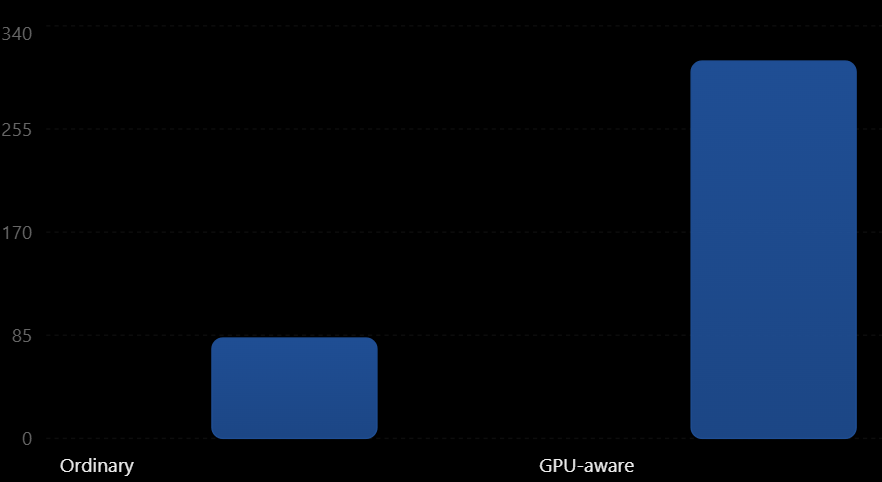

# Final Experiment 14: Ordinary vs GPU-Aware ResNet-50 Training

## 1. Objective

Compare conventional deep-learning training with GPU-aware optimized training using knowledge gained from GPU architecture experiments.

The objective is to evaluate whether hardware-aware optimization improves training throughput, execution time and GPU memory efficiency.

## 2. Experimental environment

- GPU: NVIDIA Tesla T4
- Model: ResNet-50
- Dataset: CIFAR-10
- Training samples: 10,000
- Validation samples: 2,000
- Input resolution: 224 × 224
- Batch size: 64
- Epochs: 2
- Optimizer: AdamW
- Learning rate: 0.001

Both approaches started from identical initial model weights.

## 3. Approach A: Ordinary training

- FP32 precision.
- Standard contiguous memory layout.
- Pageable CPU memory.
- Standard blocking data transfers.
- Single-process data loading (`num_workers=0`).
- Conventional gradient management.

## 4. Approach B: GPU-aware training

- FP16 mixed precision.
- Channels-last memory layout.
- Pinned CPU memory.
- Non-blocking GPU transfers.
- Parallel data loading (`num_workers=2`).
- Efficient gradient management using `set_to_none=True`.

## 5. Experimental results

| Metric | Ordinary | GPU-aware |
|---|---:|---:|
| Training time | 241.80 seconds | 64.31 seconds |
| Throughput | 82.71 images/sec | 311.01 images/sec |
| Peak GPU memory | 6.11 GB | 3.57 GB |
| Validation accuracy | 34.75% | 38.15% |

## 6. Performance analysis

### Training speedup

Speedup = Ordinary training time / Optimized training time

241.80 / 64.31 = 3.76×

The optimized approach achieved approximately 3.76 times the training throughput.

### Training time reduction

((241.80 - 64.31) / 241.80) × 100

Approximately 73.4% reduction in training time.

### Memory reduction

((6.11 - 3.57) / 6.11) × 100

Approximately 41.6% reduction in peak GPU memory allocation.

### Accuracy comparison

- Ordinary validation accuracy: 34.75%.
- GPU-aware validation accuracy: 38.15%.
- Difference: +3.40 percentage points.

The optimized approach achieved higher validation accuracy in this run. Repeated experiments are required to establish whether this difference is reproducible.

## 7. Observations

1. GPU-aware training significantly reduced execution time.
2. Training throughput increased from 82.71 to 311.01 images per second.
3. Peak GPU memory allocation decreased from 6.11 GB to 3.57 GB.
4. Validation accuracy was higher in the optimized run.
5. Both configurations completed training successfully.

## 8. Conclusion

This experiment demonstrates the practical value of GPU-aware optimization.

By combining mixed precision, channels-last memory layout, pinned memory, non-blocking transfers and parallel data loading, the optimized approach achieved a 3.76× speedup compared with conventional training.

The experiment connects GPU architecture concepts with real-world deep-learning performance engineering.

**Final learning:** Understanding the GPU allows engineers to optimize how workloads use hardware instead of relying only on default framework configurations.

## 9. Limitations

- The comparison combines multiple optimizations, so individual contributions were not isolated.
- Only two epochs were trained.
- Results are specific to the tested GPU, model and workload.
- Accuracy differences may reflect training variability.
- Repeated runs and controlled ablation experiments are required for stronger conclusions.
